In [1]:
import sys
import numpy as np
import pandas as pd
import scipy
import sklearn
import xgboost
import matplotlib
import numba

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Numba:", numba.__version__)

Python: 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 08:22:19) [Clang 14.0.6 ]
NumPy: 1.26.4
pandas: 2.2.2
SciPy: 1.13.1
scikit-learn: 1.5.1
XGBoost: 3.4.1
Matplotlib: 3.9.2
Numba: 0.60.0


# M/M/1 Baseline — revised after supervisor feedback

## Purpose

This notebook has two clearly separated roles:

1. **Main role: simulator validation.** Validate the M/M/1 simulator against the analytical steady-state quantities \(L\), \(L_q\), \(W\), and \(W_q\).
2. **Supplementary role: one-step queue-length forecasting.** Retain the existing forecasting result as supplementary work, but evaluate it using independent simulation runs.

The project's **main ML task is now steady-state performance prediction from system characteristics**. That configuration-level task will be developed in the Gamma-service M/GI/1 experiment, not here.

In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import t as student_t

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

RHO_VALUES = [0.30, 0.50, 0.70, 0.80, 0.90, 0.95]
MU = 1.0

# Revised time-based design
WARMUP_TIME = 10_000.0
RECORD_TIME = 20_000.0
DT = 1.0

N_REPLICATIONS = 30
BASE_SEED = 123

# Reliability pilot
PILOT_RHOS = [0.30, 0.70, 0.95]
PILOT_REPLICATIONS = 10

# Supplementary forecasting: 30 independent runs / rho
TRAIN_RUN_IDS = list(range(0, 20))
VAL_RUN_IDS = list(range(20, 25))
TEST_RUN_IDS = list(range(25, 30))
FORECAST_REPLICATIONS = 30

# Heavy section: enable only if you want to rerun supplementary forecasting
RUN_SUPPLEMENTARY_FORECAST = True

OUTPUT_DIR = Path("MM1_revised_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. Analytical M/M/1 steady-state values

For a stable M/M/1 queue with $\rho=\lambda/\mu<1$,
$$
L=\frac{\rho}{1-\rho},\qquad
L_q=\frac{\rho^2}{1-\rho},
$$
$$
W=\frac{1}{\mu-\lambda},\qquad
W_q=\frac{\rho}{\mu-\lambda}.
$$

These are stationary long-run performance measures used to validate the simulator.

In [2]:
def mm1_theory(lambda_rate, mu):
    if lambda_rate <= 0 or mu <= 0:
        raise ValueError("lambda and mu must be positive.")
    rho = lambda_rate / mu
    if rho >= 1:
        raise ValueError("Stable M/M/1 requires rho < 1.")

    return {
        "rho": rho,
        "L": rho / (1 - rho),
        "Lq": rho**2 / (1 - rho),
        "W": 1 / (mu - lambda_rate),
        "Wq": rho / (mu - lambda_rate),
    }

theory_rows = []
for rho in RHO_VALUES:
    lam = rho * MU
    th = mm1_theory(lam, MU)
    theory_rows.append({
        "rho": rho,
        "lambda": lam,
        "mu": MU,
        "L": th["L"],
        "Lq": th["Lq"],
        "W": th["W"],
        "Wq": th["Wq"],
    })

theory_table = pd.DataFrame(theory_rows)
theory_table.to_csv(OUTPUT_DIR / "mm1_theoretical_values.csv", index=False)
theory_table.round(4)


,rho,lambda,mu,L,Lq,W,Wq
0,0.30,0.30,1.0,0.4286,0.1286,1.4286,0.4286
1,0.50,0.50,1.0,1.0000,0.5000,2.0000,1.0000
2,0.70,0.70,1.0,2.3333,1.6333,3.3333,2.3333
3,0.80,0.80,1.0,4.0000,3.2000,5.0000,4.0000
4,0.90,0.90,1.0,9.0000,8.1000,10.0000,9.0000
5,0.95,0.95,1.0,19.0000,18.0500,20.0000,19.0000


## 2. Time-horizon M/M/1 simulator

The revised design uses a **fixed time horizon** rather than a fixed customer count.

For each run:
- arrivals continue throughout the recording horizon;
- a warm-up period is discarded;
- **$L$ and $L_q$ are averaged only over the fixed recording window;**
- no artificial draining period is included in stationary time averages;
- customers arriving during the measurement window are followed to completion so their full \(W\) and \(W_q\) are available.


In [3]:
def simulate_mm1_horizon(lambda_rate, mu, horizon, seed=123, chunk_size=10_000):
    """Simulate an M/M/1 queue with arrivals generated up to a fixed time horizon."""
    if lambda_rate <= 0 or mu <= 0:
        raise ValueError("lambda_rate and mu must be positive.")
    if horizon <= 0:
        raise ValueError("horizon must be positive.")

    rng = np.random.default_rng(seed)

    arrival_chunks = []
    current_time = 0.0

    while True:
        interarrival = rng.exponential(scale=1 / lambda_rate, size=chunk_size)
        candidate_times = current_time + np.cumsum(interarrival)

        within = candidate_times[candidate_times <= horizon]
        if len(within) > 0:
            arrival_chunks.append(within)

        if candidate_times[-1] > horizon:
            break

        current_time = candidate_times[-1]

    arrival_time = (
        np.concatenate(arrival_chunks)
        if arrival_chunks
        else np.array([], dtype=float)
    )

    n_customers = len(arrival_time)
    if n_customers == 0:
        raise RuntimeError("No arrivals generated. Check settings.")

    service_time = rng.exponential(scale=1 / mu, size=n_customers)

    service_start = np.zeros(n_customers)
    departure_time = np.zeros(n_customers)

    service_start[0] = arrival_time[0]
    departure_time[0] = service_start[0] + service_time[0]

    for i in range(1, n_customers):
        service_start[i] = max(arrival_time[i], departure_time[i - 1])
        departure_time[i] = service_start[i] + service_time[i]

    waiting_time = service_start - arrival_time
    system_time = departure_time - arrival_time

    return pd.DataFrame({
        "customer_id": np.arange(n_customers),
        "arrival_time": arrival_time,
        "service_start": service_start,
        "service_time": service_time,
        "departure_time": departure_time,
        "waiting_time": waiting_time,
        "system_time": system_time,
    })


In [4]:
# Quick smoke test
rho_test = 0.70
customers_test = simulate_mm1_horizon(
    lambda_rate=rho_test * MU,
    mu=MU,
    horizon=200.0,
    seed=BASE_SEED
)
customers_test.head()


,customer_id,arrival_time,service_start,service_time,departure_time,waiting_time,system_time
0,0,0.852818,0.852818,2.438909,3.291727,0.000000,2.438909
1,1,1.020005,3.291727,0.024391,3.316118,2.271722,2.296113
2,2,1.379712,3.316118,2.291588,5.607705,1.936406,4.227993
3,3,1.819662,5.607705,0.116864,5.724569,3.788043,3.904907
4,4,1.950809,5.724569,1.271929,6.996498,3.773760,5.045689


## 3. Fixed-window performance estimation

\(L\) and \(L_q\) are time averages over the post-warm-up recording window.

For \(W\) and \(W_q\), the measurement cohort is defined by **arrival time**: customers arriving during the recording window are included even if they depart after the recording horizon.


In [5]:
def time_average_state(customers, start_time, end_time):
    """Time-average N(t) and Q(t) over [start_time, end_time]."""
    arrivals = customers["arrival_time"].to_numpy()
    departures = customers["departure_time"].to_numpy()

    n_initial = (
        np.searchsorted(arrivals, start_time, side="right")
        - np.searchsorted(departures, start_time, side="right")
    )

    a0 = np.searchsorted(arrivals, start_time, side="right")
    a1 = np.searchsorted(arrivals, end_time, side="right")
    d0 = np.searchsorted(departures, start_time, side="right")
    d1 = np.searchsorted(departures, end_time, side="right")

    arrival_events = arrivals[a0:a1]
    departure_events = departures[d0:d1]

    event_times = np.concatenate([arrival_events, departure_events])
    event_changes = np.concatenate([
        np.ones(len(arrival_events), dtype=int),
        -np.ones(len(departure_events), dtype=int),
    ])

    if len(event_times) == 0:
        return float(n_initial), float(max(n_initial - 1, 0))

    order = np.argsort(event_times, kind="mergesort")
    event_times = event_times[order]
    event_changes = event_changes[order]

    durations = np.diff(np.concatenate([[start_time], event_times, [end_time]]))
    states = np.concatenate([[n_initial], n_initial + np.cumsum(event_changes)])

    area_L = np.dot(states, durations)
    area_Lq = np.dot(np.maximum(states - 1, 0), durations)

    total_time = end_time - start_time
    return area_L / total_time, area_Lq / total_time


def summarize_replication(customers, lambda_rate, mu, warmup_time, record_time):
    start_time = warmup_time
    end_time = warmup_time + record_time

    L_sim, Lq_sim = time_average_state(customers, start_time, end_time)

    cohort = customers[
        (customers["arrival_time"] >= start_time)
        & (customers["arrival_time"] < end_time)
    ]

    W_sim = cohort["system_time"].mean()
    Wq_sim = cohort["waiting_time"].mean()

    lambda_hat = len(cohort) / record_time
    mu_hat = 1 / cohort["service_time"].mean()

    return {
        "L_sim": L_sim,
        "Lq_sim": Lq_sim,
        "W_sim": W_sim,
        "Wq_sim": Wq_sim,
        "lambda_hat": lambda_hat,
        "mu_hat": mu_hat,
        "n_arrivals_recorded": len(cohort),
    }


## 4. Simulator validation with 30 independent replications

The 95% confidence interval uses the Student-\(t\) critical value:

\[
\bar{x}\pm t_{0.975,R-1}\frac{s}{\sqrt{R}},
\]

where \(R=30\) and \(s\) is the standard deviation of the **replication-level estimates**.


In [6]:
def run_validation_experiment(
    rhos, mu, warmup_time, record_time, replications, base_seed
):
    rows = []
    horizon = warmup_time + record_time

    for scenario_id, rho in enumerate(rhos):
        lam = rho * mu
        theory = mm1_theory(lam, mu)
        print(f"Validation: rho={rho:.2f}")

        for rep in range(replications):
            seed = base_seed + scenario_id * 10_000 + rep

            customers = simulate_mm1_horizon(
                lambda_rate=lam,
                mu=mu,
                horizon=horizon,
                seed=seed
            )

            sim = summarize_replication(
                customers=customers,
                lambda_rate=lam,
                mu=mu,
                warmup_time=warmup_time,
                record_time=record_time
            )

            rows.append({
                "rho": rho,
                "lambda": lam,
                "mu": mu,
                "replication": rep + 1,
                "warmup_time": warmup_time,
                "record_time": record_time,

                "L_theory": theory["L"],
                "Lq_theory": theory["Lq"],
                "W_theory": theory["W"],
                "Wq_theory": theory["Wq"],

                "L_sim": sim["L_sim"],
                "Lq_sim": sim["Lq_sim"],
                "W_sim": sim["W_sim"],
                "Wq_sim": sim["Wq_sim"],

                "lambda_hat": sim["lambda_hat"],
                "mu_hat": sim["mu_hat"],
                "n_arrivals_recorded": sim["n_arrivals_recorded"],
            })

    return pd.DataFrame(rows)


def create_validation_summary(replication_results):
    summary_rows = []

    for (rho, lam, mu), group in replication_results.groupby(
        ["rho", "lambda", "mu"], sort=True
    ):
        R = len(group)
        t_crit = student_t.ppf(0.975, df=R - 1)

        row = {
            "rho": rho,
            "lambda": lam,
            "mu": mu,
            "replications": R,
            "t_critical": t_crit,
        }

        for metric in ["L", "Lq", "W", "Wq"]:
            theory_value = group[f"{metric}_theory"].iloc[0]
            estimates = group[f"{metric}_sim"]

            sim_mean = estimates.mean()
            sim_sd = estimates.std(ddof=1)
            ci_hw = t_crit * sim_sd / np.sqrt(R)

            abs_error = abs(sim_mean - theory_value)
            pct_error = abs_error / abs(theory_value) * 100

            row[f"{metric}_theory"] = theory_value
            row[f"{metric}_sim_mean"] = sim_mean
            row[f"{metric}_rep_sd"] = sim_sd
            row[f"{metric}_95CI_halfwidth"] = ci_hw
            row[f"{metric}_95CI_low"] = sim_mean - ci_hw
            row[f"{metric}_95CI_high"] = sim_mean + ci_hw
            row[f"{metric}_abs_error"] = abs_error
            row[f"{metric}_pct_error"] = pct_error

        row["lambda_hat_mean"] = group["lambda_hat"].mean()
        row["mu_hat_mean"] = group["mu_hat"].mean()
        row["mean_arrivals_recorded"] = group["n_arrivals_recorded"].mean()

        summary_rows.append(row)

    return pd.DataFrame(summary_rows)


In [7]:
replication_results = run_validation_experiment(
    rhos=RHO_VALUES,
    mu=MU,
    warmup_time=WARMUP_TIME,
    record_time=RECORD_TIME,
    replications=N_REPLICATIONS,
    base_seed=BASE_SEED
)

validation_summary = create_validation_summary(replication_results)

replication_results.to_csv(
    OUTPUT_DIR / "mm1_validation_replications.csv",
    index=False
)
validation_summary.to_csv(
    OUTPUT_DIR / "mm1_validation_summary.csv",
    index=False
)

validation_summary[
    [
        "rho",
        "Lq_theory", "Lq_sim_mean", "Lq_95CI_low", "Lq_95CI_high", "Lq_pct_error",
        "Wq_theory", "Wq_sim_mean", "Wq_95CI_low", "Wq_95CI_high", "Wq_pct_error",
    ]
].round(4)


Validation: rho=0.30
Validation: rho=0.50
Validation: rho=0.70
Validation: rho=0.80
Validation: rho=0.90
Validation: rho=0.95


,rho,Lq_theory,Lq_sim_mean,Lq_95CI_low,Lq_95CI_high,Lq_pct_error,Wq_theory,Wq_sim_mean,Wq_95CI_low,Wq_95CI_high,Wq_pct_error
0,0.30,0.1286,0.1296,0.1262,0.1329,0.7668,0.4286,0.4319,0.4217,0.4420,0.7655
1,0.50,0.5000,0.4957,0.4842,0.5072,0.8612,1.0000,0.9920,0.9715,1.0124,0.8026
2,0.70,1.6333,1.6172,1.5732,1.6612,0.9872,2.3333,2.3148,2.2569,2.3727,0.7940
3,0.80,3.2000,3.1884,3.0422,3.3346,0.3629,4.0000,3.9931,3.8187,4.1674,0.1736
4,0.90,8.1000,8.1088,7.5506,8.6669,0.1084,9.0000,9.0032,8.3966,9.6097,0.0353
5,0.95,18.0500,16.9321,15.4143,18.4499,6.1932,19.0000,17.8221,16.2435,19.4006,6.1997


### Validation plots
These compare analytical steady-state values with independent-replication simulation estimates.


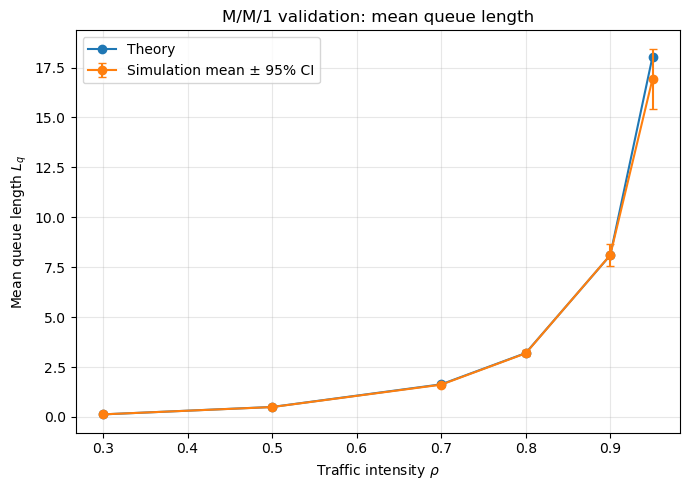

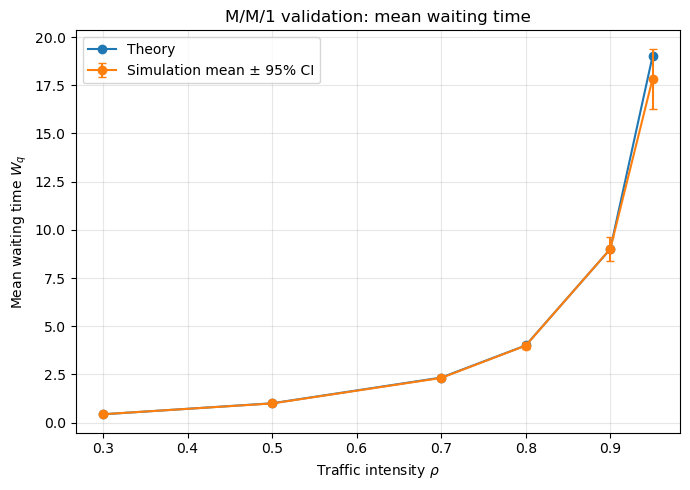

In [35]:
plt.figure(figsize=(7, 5))
plt.plot(validation_summary["rho"], validation_summary["Lq_theory"],
         marker="o", label="Theory")
plt.errorbar(validation_summary["rho"], validation_summary["Lq_sim_mean"],
             yerr=validation_summary["Lq_95CI_halfwidth"],
             marker="o", capsize=3, label="Simulation mean ± 95% CI")
plt.xlabel(r"Traffic intensity $\rho$")
plt.ylabel(r"Mean queue length $L_q$")
plt.title("M/M/1 validation: mean queue length")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mm1_validation_Lq.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(validation_summary["rho"], validation_summary["Wq_theory"],
         marker="o", label="Theory")
plt.errorbar(validation_summary["rho"], validation_summary["Wq_sim_mean"],
             yerr=validation_summary["Wq_95CI_halfwidth"],
             marker="o", capsize=3, label="Simulation mean ± 95% CI")
plt.xlabel(r"Traffic intensity $\rho$")
plt.ylabel(r"Mean waiting time $W_q$")
plt.title("M/M/1 validation: mean waiting time")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mm1_validation_Wq.png", dpi=300)
plt.show()


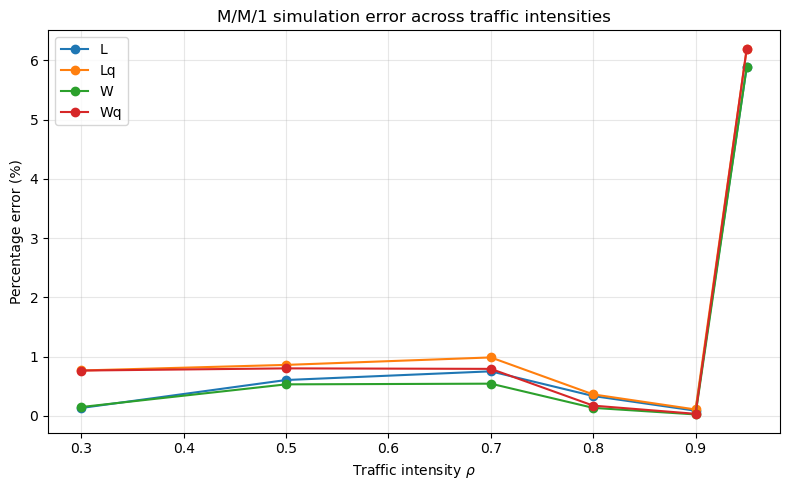

In [36]:
plt.figure(figsize=(8, 5))
for metric, label in [("L", "L"), ("Lq", "Lq"), ("W", "W"), ("Wq", "Wq")]:
    plt.plot(
        validation_summary["rho"],
        validation_summary[f"{metric}_pct_error"],
        marker="o",
        label=label
    )

plt.xlabel(r"Traffic intensity $\rho$")
plt.ylabel("Percentage error (%)")
plt.title("M/M/1 simulation error across traffic intensities")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mm1_validation_percentage_error.png", dpi=300)
plt.show()


## 5. Reliability pilot: warm-up and recording length

A small pilot checks whether the estimated steady-state labels materially change when:
- warm-up is increased;
- recording duration is increased.

If heavy-traffic estimates remain unstable, increase run length before using that design to generate stationary training labels in later experiments.


In [37]:
def run_reliability_pilot(
    rhos=PILOT_RHOS,
    mu=MU,
    replications=PILOT_REPLICATIONS,
    base_seed=90_000
):
    designs = [
        ("base", 10_000.0, 20_000.0),
        ("longer_warmup", 20_000.0, 20_000.0),
        ("longer_record", 10_000.0, 40_000.0),
    ]

    pilot_rows = []

    for design_id, warmup_time, record_time in designs:
        reps = run_validation_experiment(
            rhos=rhos,
            mu=mu,
            warmup_time=warmup_time,
            record_time=record_time,
            replications=replications,
            base_seed=base_seed + int(warmup_time + record_time)
        )

        summary = create_validation_summary(reps)
        summary["design"] = design_id
        summary["warmup_time"] = warmup_time
        summary["record_time"] = record_time
        pilot_rows.append(summary)

    return pd.concat(pilot_rows, ignore_index=True)

pilot_summary = run_reliability_pilot()

pilot_summary.to_csv(
    OUTPUT_DIR / "mm1_reliability_pilot.csv",
    index=False
)

pilot_summary[
    [
        "design", "rho", "warmup_time", "record_time",
        "Lq_sim_mean", "Lq_pct_error",
        "Wq_sim_mean", "Wq_pct_error"
    ]
].round(4)


Validation: rho=0.30
Validation: rho=0.70
Validation: rho=0.95
Validation: rho=0.30
Validation: rho=0.70
Validation: rho=0.95
Validation: rho=0.30
Validation: rho=0.70
Validation: rho=0.95


,design,rho,warmup_time,record_time,Lq_sim_mean,Lq_pct_error,Wq_sim_mean,Wq_pct_error
0,base,0.30,10000.0,20000.0,0.1293,0.5766,0.4286,0.0002
1,base,0.70,10000.0,20000.0,1.6199,0.8249,2.3198,0.5808
2,base,0.95,10000.0,20000.0,18.9077,4.7516,19.9199,4.8417
3,longer_warmup,0.30,20000.0,20000.0,0.1251,2.6877,0.4180,2.4687
4,longer_warmup,0.70,20000.0,20000.0,1.6592,1.5854,2.3652,1.3655
5,longer_warmup,0.95,20000.0,20000.0,18.6798,3.4894,19.6440,3.3892
6,longer_record,0.30,10000.0,40000.0,0.1276,0.7782,0.4254,0.7382
7,longer_record,0.70,10000.0,40000.0,1.6639,1.8745,2.3806,2.0248
8,longer_record,0.95,10000.0,40000.0,17.5340,2.8586,18.4784,2.7452


## 6. Supplementary Dynamic Forecasting

The main project task is now **configuration-level stationary-performance
prediction**. The interval-level forecasting experiments are retained only as
supplementary work.

Following the supervisor's feedback, two principal dynamic forecasting outcomes
are retained:

1. **One-step-ahead queue length**
   
   \[
   (Q_{t-19},\ldots,Q_t)\rightarrow Q_{t+1}.
   \]

2. **Next-interval mean waiting time**
   
   \[
   \mathbf{x}_t \rightarrow \bar W_{q,t+1},
   \]

   where \(\bar W_{q,t+1}\) is the mean queueing waiting time of customers whose
   service is completed during interval \(t+1\).

These are **dynamic forecasting targets** and are distinct from the stationary
quantities \(L_q\) and \(W_q\).

### Revised evaluation design

For each traffic intensity \(\rho\):

- 30 independent simulation runs are generated;
- runs 0--19 are used for training;
- runs 20--24 are reserved for validation;
- runs 25--29 are used for final testing;
- lagged features are constructed within each run only;
- no feature window is allowed to cross a simulation-run boundary.

The queue-length experiment retains the persistence baseline

\[
\widehat Q_{t+1}=Q_t.
\]

The waiting-time experiment does not use a persistence baseline because the
interval-level waiting-time target is not defined in intervals with no service
completion.

Further lookback-window, additional-target, and feature-ablation experiments
are deferred because dynamic forecasting is supplementary to the main
stationary-performance prediction task.

In [8]:
# ============================================================
# 6.1 Interval-level data for supplementary dynamic forecasting
# ============================================================

def create_dynamic_interval_data(
    customers,
    rho,
    run_id,
    warmup_time,
    record_time,
    dt=1.0,
    arrival_rate_window=20,
):
    """
    Convert one complete M/M/1 simulation run into interval-level data.

    Each interval contains:
    - queue length at the interval end;
    - number of arrivals during the interval;
    - number of departures/service completions during the interval;
    - mean queue waiting time of customers completing service;
    - recent rolling arrival-rate estimate.

    Notes
    -----
    1. Queue length is the number WAITING, excluding a customer in service.
    2. The waiting-time interval variable is defined from customers whose
       service completion/departure occurs in that interval.
    3. If no customer completes service in an interval, the interval-level
       mean waiting time is NaN rather than zero.
    """

    start_time = warmup_time
    end_time = warmup_time + record_time

    n_intervals = int(round(record_time / dt))

    # Interval boundaries:
    # (edge_i, edge_{i+1}]
    edges = start_time + np.arange(n_intervals + 1) * dt

    left_edges = edges[:-1]
    right_edges = edges[1:]

    arrivals = customers["arrival_time"].to_numpy()
    departures = customers["departure_time"].to_numpy()
    waiting_times = customers["waiting_time"].to_numpy()

    # --------------------------------------------------------
    # A. Queue state at END of each interval
    # --------------------------------------------------------

    number_in_system = (
        np.searchsorted(
            arrivals,
            right_edges,
            side="right"
        )
        -
        np.searchsorted(
            departures,
            right_edges,
            side="right"
        )
    )

    # Single-server queue:
    # if N(t) > 0, one customer can be in service.
    queue_length = np.maximum(
        number_in_system - 1,
        0
    )

    # --------------------------------------------------------
    # B. Arrivals during each interval
    # --------------------------------------------------------

    arrival_count = (
        np.searchsorted(
            arrivals,
            right_edges,
            side="right"
        )
        -
        np.searchsorted(
            arrivals,
            left_edges,
            side="right"
        )
    )

    # --------------------------------------------------------
    # C. Departures / service completions during each interval
    # --------------------------------------------------------

    departure_count = (
        np.searchsorted(
            departures,
            right_edges,
            side="right"
        )
        -
        np.searchsorted(
            departures,
            left_edges,
            side="right"
        )
    )

    # --------------------------------------------------------
    # D. Mean queue waiting time of customers whose
    #    service completes during each interval
    # --------------------------------------------------------

    # For departure exactly on an interval boundary,
    # side="left" assigns it to the preceding interval:
    # (left, right].
    dep_interval_index = (
        np.searchsorted(
            edges,
            departures,
            side="left"
        )
        - 1
    )

    valid_departure = (
        (dep_interval_index >= 0)
        &
        (dep_interval_index < n_intervals)
    )

    valid_dep_idx = dep_interval_index[
        valid_departure
    ]

    valid_waiting_times = waiting_times[
        valid_departure
    ]

    completion_count = np.bincount(
        valid_dep_idx,
        minlength=n_intervals
    )

    waiting_time_sum = np.bincount(
        valid_dep_idx,
        weights=valid_waiting_times,
        minlength=n_intervals
    )

    mean_waiting_completed = np.full(
        n_intervals,
        np.nan,
        dtype=float
    )

    has_completion = completion_count > 0

    mean_waiting_completed[
        has_completion
    ] = (
        waiting_time_sum[has_completion]
        /
        completion_count[has_completion]
    )

    # --------------------------------------------------------
    # E. Construct dataframe
    # --------------------------------------------------------

    df = pd.DataFrame({
        "rho": rho,
        "run_id": run_id,
        "interval_index": np.arange(
            n_intervals
        ),
        "time": (
            right_edges - start_time
        ),
        "queue_length": queue_length,
        "arrivals": arrival_count,
        "departures": departure_count,
        "completion_count": completion_count,
        "mean_waiting_completed":
            mean_waiting_completed,
    })

    # --------------------------------------------------------
    # F. Recent arrival-rate estimate
    #
    # lambda_hat_t =
    # sum(A_{t-19}, ..., A_t) / (20 * dt)
    # --------------------------------------------------------

    df["recent_arrival_rate"] = (
        df["arrivals"]
        .rolling(
            window=arrival_rate_window,
            min_periods=arrival_rate_window
        )
        .sum()
        /
        (
            arrival_rate_window * dt
        )
    )

    return df


# ============================================================
# 6.2 Generate independent forecasting runs
# ============================================================

def generate_forecasting_runs(
    rhos,
    mu,
    replications,
    warmup_time,
    record_time,
    dt,
    base_seed,
):
    """
    Generate independent simulation runs for each rho.

    The SAME runs are subsequently used for:
    - queue-length forecasting;
    - waiting-time forecasting.

    This ensures the two supplementary tasks are based on
    the same simulated environments.
    """

    frames = []

    horizon = (
        warmup_time + record_time
    )

    for scenario_id, rho in enumerate(rhos):

        lam = rho * mu

        for run_id in range(replications):

            seed = (
                base_seed
                + scenario_id * 10_000
                + run_id
            )

            customers = simulate_mm1_horizon(
                lambda_rate=lam,
                mu=mu,
                horizon=horizon,
                seed=seed
            )

            interval_df = (
                create_dynamic_interval_data(
                    customers=customers,
                    rho=rho,
                    run_id=run_id,
                    warmup_time=warmup_time,
                    record_time=record_time,
                    dt=dt,
                    arrival_rate_window=20,
                )
            )

            frames.append(interval_df)

    return pd.concat(
        frames,
        ignore_index=True
    )


# ============================================================
# 6.3 Queue-length forecasting dataset
# ============================================================

def create_q_forecast_dataset(
    interval_data,
    history_length=20,
    horizon_steps=1,
):
    """
    Construct:
        (Q_{t-19}, ..., Q_t) -> Q_{t+1}

    Lags are constructed separately within each
    rho/run_id combination.
    """

    if history_length < 1:
        raise ValueError(
            "history_length must be >= 1."
        )

    if horizon_steps != 1:
        raise ValueError(
            "The current supplementary experiment "
            "uses one-step-ahead forecasting only."
        )

    df = interval_data.sort_values(
        [
            "rho",
            "run_id",
            "interval_index"
        ]
    ).copy()

    group_cols = [
        "rho",
        "run_id"
    ]

    # Current state
    df["Q_t"] = df[
        "queue_length"
    ]

    # Previous states
    for lag in range(
        1,
        history_length
    ):

        df[
            f"Q_t_minus_{lag}"
        ] = (
            df
            .groupby(group_cols)[
                "queue_length"
            ]
            .shift(lag)
        )

    # Next-interval target
    target_col = "Q_t_plus_1"

    df[target_col] = (
        df
        .groupby(group_cols)[
            "queue_length"
        ]
        .shift(-1)
    )

    feature_cols = (
        [
            f"Q_t_minus_{lag}"
            for lag in range(
                history_length - 1,
                0,
                -1
            )
        ]
        +
        ["Q_t"]
    )

    keep_cols = [
        "rho",
        "run_id",
        "interval_index",
        *feature_cols,
        target_col,
    ]

    result = (
        df[keep_cols]
        .dropna()
        .reset_index(drop=True)
    )

    return (
        result,
        feature_cols,
        target_col
    )


# ============================================================
# 6.4 Waiting-time forecasting dataset
# ============================================================

def create_wq_forecast_dataset(
    interval_data,
    history_length=20,
    horizon_steps=1,
):
    """
    Construct the supplementary next-interval waiting-time task.

    Target
    ------
    Wq_t_plus_1:
        mean queue waiting time of customers whose service
        completes during interval t+1.

    Features
    --------
    Q-history:
        Q_{t-19}, ..., Q_t

    plus current operational information:
        arrivals_t
        departures_t
        recent_arrival_rate_t

    Important
    ---------
    If interval t+1 contains no service completion,
    the target is undefined and that row is excluded.
    It must NOT be coded as zero waiting time.
    """

    if history_length < 1:
        raise ValueError(
            "history_length must be >= 1."
        )

    if horizon_steps != 1:
        raise ValueError(
            "The current supplementary experiment "
            "uses one-step-ahead forecasting only."
        )

    df = interval_data.sort_values(
        [
            "rho",
            "run_id",
            "interval_index"
        ]
    ).copy()

    group_cols = [
        "rho",
        "run_id"
    ]

    # Current queue state
    df["Q_t"] = df[
        "queue_length"
    ]

    # Previous queue states
    for lag in range(
        1,
        history_length
    ):

        df[
            f"Q_t_minus_{lag}"
        ] = (
            df
            .groupby(group_cols)[
                "queue_length"
            ]
            .shift(lag)
        )

    # --------------------------------------------------------
    # Next-interval waiting-time target
    # --------------------------------------------------------

    target_col = "Wq_t_plus_1"

    df[target_col] = (
        df
        .groupby(group_cols)[
            "mean_waiting_completed"
        ]
        .shift(-1)
    )

    # --------------------------------------------------------
    # Features
    # --------------------------------------------------------

    feature_cols = (
        [
            f"Q_t_minus_{lag}"
            for lag in range(
                history_length - 1,
                0,
                -1
            )
        ]
        +
        [
            "Q_t",
            "arrivals",
            "departures",
            "recent_arrival_rate",
        ]
    )

    keep_cols = [
        "rho",
        "run_id",
        "interval_index",
        *feature_cols,
        target_col,
    ]

    result = (
        df[keep_cols]
        .dropna()
        .reset_index(drop=True)
    )

    return (
        result,
        feature_cols,
        target_col
    )


# ============================================================
# 6.5 Split complete runs into train / validation / test
# ============================================================

def split_forecast_by_run(
    prediction_df
):
    """
    Keep complete independent runs together.

    Current split:
        runs 0-19  -> training
        runs 20-24 -> validation
        runs 25-29 -> final testing
    """

    train_df = prediction_df[
        prediction_df[
            "run_id"
        ].isin(TRAIN_RUN_IDS)
    ].copy()

    val_df = prediction_df[
        prediction_df[
            "run_id"
        ].isin(VAL_RUN_IDS)
    ].copy()

    test_df = prediction_df[
        prediction_df[
            "run_id"
        ].isin(TEST_RUN_IDS)
    ].copy()

    return (
        train_df,
        val_df,
        test_df
    )

In [9]:
# ============================================================
# 6.6 Queue-length forecasting models
# ============================================================

def fit_q_forecast_models(
    train_df,
    test_df,
    feature_cols,
    target_col,
):
    """
    Fit four regression models plus persistence baseline
    for one-step-ahead queue-length forecasting.
    """

    X_train = train_df[
        feature_cols
    ]

    y_train = train_df[
        target_col
    ]

    X_test = test_df[
        feature_cols
    ]

    y_test = test_df[
        target_col
    ]

    models = {

        "Linear Regression":
            LinearRegression(),

        "Decision Tree":
            DecisionTreeRegressor(
                random_state=123
            ),

        "Random Forest":
            RandomForestRegressor(
                n_estimators=100,
                random_state=123,
                n_jobs=-1
            ),

        "XGBoost":
            XGBRegressor(
                n_estimators=100,
                objective="reg:squarederror",
                random_state=123,
                n_jobs=-1,
                verbosity=0
            ),
    }

    predictions = test_df[
        [
            "rho",
            "run_id",
            "interval_index",
            target_col,
            "Q_t",
        ]
    ].copy()

    results = []

    # --------------------------------------------------------
    # Persistence baseline
    #
    # Q_hat_{t+1} = Q_t
    # --------------------------------------------------------

    y_persistence = test_df[
        "Q_t"
    ].to_numpy()

    results.append({

        "Model":
            "Persistence",

        "MAE":
            mean_absolute_error(
                y_test,
                y_persistence
            ),

        "RMSE":
            np.sqrt(
                mean_squared_error(
                    y_test,
                    y_persistence
                )
            ),

        "R2":
            r2_score(
                y_test,
                y_persistence
            ),
    })

    predictions[
        "Persistence"
    ] = y_persistence

    # --------------------------------------------------------
    # ML models
    # --------------------------------------------------------

    trained_models = {}

    for model_name, model in models.items():

        model.fit(
            X_train,
            y_train
        )

        y_pred = model.predict(
            X_test
        )

        results.append({

            "Model":
                model_name,

            "MAE":
                mean_absolute_error(
                    y_test,
                    y_pred
                ),

            "RMSE":
                np.sqrt(
                    mean_squared_error(
                        y_test,
                        y_pred
                    )
                ),

            "R2":
                r2_score(
                    y_test,
                    y_pred
                ),
        })

        predictions[
            model_name
        ] = y_pred

        trained_models[
            model_name
        ] = model

    return (
        pd.DataFrame(results),
        predictions,
        trained_models
    )


# ============================================================
# 6.7 Waiting-time forecasting models
# ============================================================

def fit_wq_forecast_models(
    train_df,
    test_df,
    feature_cols,
    target_col,
):
    """
    Fit the same four regression models for next-interval
    mean waiting-time forecasting.

    No persistence baseline is included because the
    interval-level waiting-time target is not available
    in intervals without service completions.
    """

    X_train = train_df[
        feature_cols
    ]

    y_train = train_df[
        target_col
    ]

    X_test = test_df[
        feature_cols
    ]

    y_test = test_df[
        target_col
    ]

    models = {

        "Linear Regression":
            LinearRegression(),

        "Decision Tree":
            DecisionTreeRegressor(
                random_state=123
            ),

        "Random Forest":
            RandomForestRegressor(
                n_estimators=100,
                random_state=123,
                n_jobs=-1
            ),

        "XGBoost":
            XGBRegressor(
                n_estimators=100,
                objective="reg:squarederror",
                random_state=123,
                n_jobs=-1,
                verbosity=0
            ),
    }

    predictions = test_df[
        [
            "rho",
            "run_id",
            "interval_index",
            target_col,
        ]
    ].copy()

    results = []
    trained_models = {}

    for model_name, model in models.items():

        model.fit(
            X_train,
            y_train
        )

        y_pred = model.predict(
            X_test
        )

        results.append({

            "Model":
                model_name,

            "MAE":
                mean_absolute_error(
                    y_test,
                    y_pred
                ),

            "RMSE":
                np.sqrt(
                    mean_squared_error(
                        y_test,
                        y_pred
                    )
                ),

            "R2":
                r2_score(
                    y_test,
                    y_pred
                ),
        })

        predictions[
            model_name
        ] = y_pred

        trained_models[
            model_name
        ] = model

    return (
        pd.DataFrame(results),
        predictions,
        trained_models
    )


# ============================================================
# 6.8 Generic evaluation by rho
# ============================================================

def evaluate_forecast_by_rho(
    predictions,
    target_col,
    model_cols,
):
    """
    Evaluate each model separately within each traffic
    intensity using the final test runs only.
    """

    rows = []

    for rho, group in (
        predictions
        .groupby("rho")
    ):

        y_true = group[
            target_col
        ]

        for model_name in model_cols:

            y_pred = group[
                model_name
            ]

            rows.append({

                "rho":
                    rho,

                "Model":
                    model_name,

                "MAE":
                    mean_absolute_error(
                        y_true,
                        y_pred
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            y_true,
                            y_pred
                        )
                    ),

                "R2":
                    r2_score(
                        y_true,
                        y_pred
                    ),
            })

    return pd.DataFrame(rows)


# ============================================================
# 6.9 Convert long by-rho result to wide RMSE table
# ============================================================

def make_rmse_by_rho_table(
    result_by_rho
):
    """
    Convert:
        rho | Model | RMSE
    into:
        rho | model1 | model2 | ...

    Useful for Overleaf.
    """

    wide = (
        result_by_rho
        .pivot(
            index="rho",
            columns="Model",
            values="RMSE"
        )
        .reset_index()
    )

    wide.columns.name = None

    return wide

Generating independent forecasting runs...
Interval-level rows: 3600000

QUEUE-LENGTH FORECASTING
Queue-length dataset rows:
  train: 2397600
  validation: 599400
  test: 599400

NEXT-INTERVAL WAITING-TIME FORECASTING
Waiting-time dataset rows:
  train: 1164802
  validation: 290986
  test: 290688


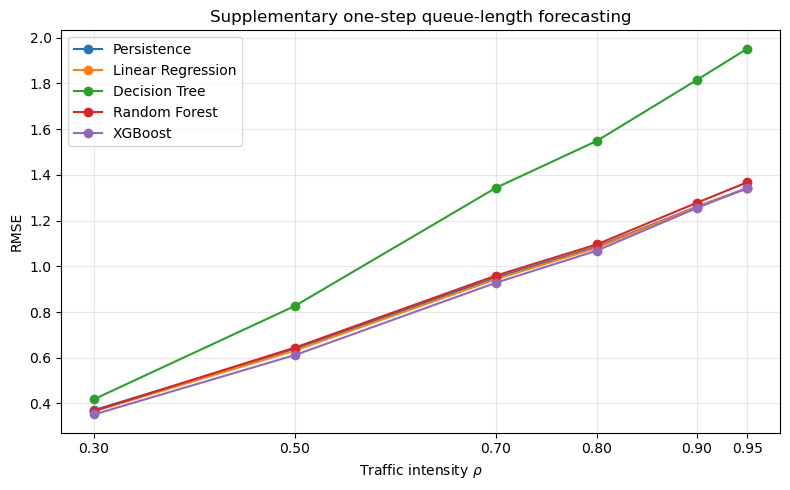

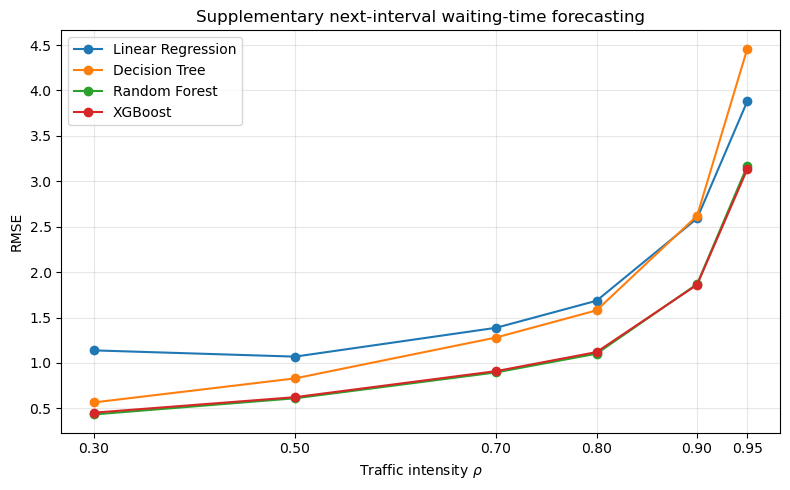


Queue-length overall results:


,Model,MAE,RMSE,R2
0,Persistence,0.580609,1.001410,0.992782
1,Linear Regression,0.602811,0.998462,0.992824
2,Decision Tree,0.890704,1.424101,0.985402
3,Random Forest,0.674000,1.014526,0.992592
4,XGBoost,0.646910,0.989816,0.992948



Queue-length RMSE by rho:


,rho,Decision Tree,Linear Regression,Persistence,Random Forest,XGBoost
0,0.30,0.418711,0.365702,0.370739,0.367623,0.351990
1,0.50,0.826935,0.631862,0.639264,0.644605,0.611811
2,0.70,1.343634,0.943804,0.950417,0.959466,0.928238
3,0.80,1.548037,1.080356,1.085365,1.095406,1.068158
4,0.90,1.815637,1.259948,1.261539,1.278166,1.255316
5,0.95,1.952162,1.342819,1.340906,1.367740,1.342313



Waiting-time overall results:


,Model,MAE,RMSE,R2
0,Linear Regression,1.491860,2.385863,0.967578
1,Decision Tree,1.285045,2.545818,0.963085
2,Random Forest,0.918999,1.808798,0.981365
3,XGBoost,0.931160,1.797918,0.981589


... (2 outputs left out)


Waiting-time target coverage:


,rho,total_intervals,intervals_with_completion,completion_interval_pct
0,0.30,600000,155615,25.935833
1,0.50,600000,235268,39.211333
2,0.70,600000,302695,50.449167
3,0.80,600000,330087,55.014500
4,0.90,600000,355766,59.294333
5,0.95,600000,368763,61.460500



Combined supplementary summary:


,Target,Model,MAE,RMSE,R2
0,Queue length,Persistence,0.580609,1.001410,0.992782
1,Queue length,Linear Regression,0.602811,0.998462,0.992824
2,Queue length,Decision Tree,0.890704,1.424101,0.985402
3,Queue length,Random Forest,0.674000,1.014526,0.992592
4,Queue length,XGBoost,0.646910,0.989816,0.992948
5,Waiting time,Linear Regression,1.491860,2.385863,0.967578
6,Waiting time,Decision Tree,1.285045,2.545818,0.963085
7,Waiting time,Random Forest,0.918999,1.808798,0.981365
8,Waiting time,XGBoost,0.931160,1.797918,0.981589


In [10]:
# ============================================================
# 6.10 Run supplementary dynamic forecasting
# ============================================================

if RUN_SUPPLEMENTARY_FORECAST:

    # ========================================================
    # STEP 1
    # Generate the SAME 30 independent runs per rho
    # for both supplementary forecasting targets.
    # ========================================================

    print(
        "Generating independent forecasting runs..."
    )

    forecast_interval_data = (
        generate_forecasting_runs(
            rhos=RHO_VALUES,
            mu=MU,
            replications=FORECAST_REPLICATIONS,
            warmup_time=WARMUP_TIME,
            record_time=RECORD_TIME,
            dt=DT,
            base_seed=BASE_SEED + 200_000
        )
    )

    print(
        "Interval-level rows:",
        len(forecast_interval_data)
    )


    # ========================================================
    # STEP 2
    # Queue-length forecasting
    # ========================================================

    print(
        "\n========================================"
    )
    print(
        "QUEUE-LENGTH FORECASTING"
    )
    print(
        "========================================"
    )

    (
        q_forecast_df,
        q_feature_cols,
        q_target_col
    ) = create_q_forecast_dataset(
        forecast_interval_data,
        history_length=20,
        horizon_steps=1
    )

    (
        q_train_df,
        q_val_df,
        q_test_df
    ) = split_forecast_by_run(
        q_forecast_df
    )

    print(
        "Queue-length dataset rows:"
    )
    print(
        "  train:",
        len(q_train_df)
    )
    print(
        "  validation:",
        len(q_val_df)
    )
    print(
        "  test:",
        len(q_test_df)
    )

    (
        q_results,
        q_predictions,
        q_models
    ) = fit_q_forecast_models(
        train_df=q_train_df,
        test_df=q_test_df,
        feature_cols=q_feature_cols,
        target_col=q_target_col
    )

    q_model_cols = [
        "Persistence",
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
    ]

    q_results_by_rho = (
        evaluate_forecast_by_rho(
            predictions=q_predictions,
            target_col=q_target_col,
            model_cols=q_model_cols
        )
    )

    q_rmse_by_rho = (
        make_rmse_by_rho_table(
            q_results_by_rho
        )
    )


    # ========================================================
    # STEP 3
    # Waiting-time forecasting
    # ========================================================

    print(
        "\n========================================"
    )
    print(
        "NEXT-INTERVAL WAITING-TIME FORECASTING"
    )
    print(
        "========================================"
    )

    (
        wq_forecast_df,
        wq_feature_cols,
        wq_target_col
    ) = create_wq_forecast_dataset(
        forecast_interval_data,
        history_length=20,
        horizon_steps=1
    )

    (
        wq_train_df,
        wq_val_df,
        wq_test_df
    ) = split_forecast_by_run(
        wq_forecast_df
    )

    print(
        "Waiting-time dataset rows:"
    )
    print(
        "  train:",
        len(wq_train_df)
    )
    print(
        "  validation:",
        len(wq_val_df)
    )
    print(
        "  test:",
        len(wq_test_df)
    )

    (
        wq_results,
        wq_predictions,
        wq_models
    ) = fit_wq_forecast_models(
        train_df=wq_train_df,
        test_df=wq_test_df,
        feature_cols=wq_feature_cols,
        target_col=wq_target_col
    )

    wq_model_cols = [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
    ]

    wq_results_by_rho = (
        evaluate_forecast_by_rho(
            predictions=wq_predictions,
            target_col=wq_target_col,
            model_cols=wq_model_cols
        )
    )

    wq_rmse_by_rho = (
        make_rmse_by_rho_table(
            wq_results_by_rho
        )
    )


    # ========================================================
    # STEP 4
    # Waiting-time target coverage diagnostic
    #
    # Important because the waiting-time target exists only
    # when at least one service completion occurs.
    # ========================================================

    wq_target_coverage = (
        forecast_interval_data
        .groupby("rho")
        .agg(
            total_intervals=(
                "interval_index",
                "size"
            ),
            intervals_with_completion=(
                "mean_waiting_completed",
                "count"
            )
        )
        .reset_index()
    )

    wq_target_coverage[
        "completion_interval_pct"
    ] = (
        100
        *
        wq_target_coverage[
            "intervals_with_completion"
        ]
        /
        wq_target_coverage[
            "total_intervals"
        ]
    )


    # ========================================================
    # STEP 5
    # Combined overall summary
    # ========================================================

    q_summary = q_results.copy()

    q_summary.insert(
        0,
        "Target",
        "Queue length"
    )

    wq_summary = wq_results.copy()

    wq_summary.insert(
        0,
        "Target",
        "Waiting time"
    )

    supplementary_dynamic_forecast_summary = (
        pd.concat(
            [
                q_summary,
                wq_summary
            ],
            ignore_index=True
        )
    )


    # ========================================================
    # STEP 6
    # Save CSV outputs
    # ========================================================

    q_results.to_csv(
        OUTPUT_DIR
        / "supplementary_q_forecast_overall.csv",
        index=False
    )

    q_results_by_rho.to_csv(
        OUTPUT_DIR
        / "supplementary_q_forecast_by_rho.csv",
        index=False
    )

    q_rmse_by_rho.to_csv(
        OUTPUT_DIR
        / "supplementary_q_forecast_rmse_by_rho.csv",
        index=False
    )

    wq_results.to_csv(
        OUTPUT_DIR
        / "supplementary_wq_forecast_overall.csv",
        index=False
    )

    wq_results_by_rho.to_csv(
        OUTPUT_DIR
        / "supplementary_wq_forecast_by_rho.csv",
        index=False
    )

    wq_rmse_by_rho.to_csv(
        OUTPUT_DIR
        / "supplementary_wq_forecast_rmse_by_rho.csv",
        index=False
    )

    wq_target_coverage.to_csv(
        OUTPUT_DIR
        / "supplementary_wq_target_coverage.csv",
        index=False
    )

    supplementary_dynamic_forecast_summary.to_csv(
        OUTPUT_DIR
        / "supplementary_dynamic_forecast_summary.csv",
        index=False
    )


    # ========================================================
    # STEP 7
    # Queue-length RMSE plot by rho
    # ========================================================

    plt.figure(
        figsize=(8, 5)
    )

    for model_name in q_model_cols:

        subset = q_results_by_rho[
            q_results_by_rho[
                "Model"
            ] == model_name
        ]

        plt.plot(
            subset["rho"],
            subset["RMSE"],
            marker="o",
            label=model_name
        )

    plt.xlabel(
        r"Traffic intensity $\rho$"
    )

    plt.ylabel(
        "RMSE"
    )

    plt.title(
        "Supplementary one-step "
        "queue-length forecasting"
    )

    plt.xticks(
        RHO_VALUES
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR
        / "supplementary_q_forecast_rmse_by_rho.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


    # ========================================================
    # STEP 8
    # Waiting-time RMSE plot by rho
    # ========================================================

    plt.figure(
        figsize=(8, 5)
    )

    for model_name in wq_model_cols:

        subset = wq_results_by_rho[
            wq_results_by_rho[
                "Model"
            ] == model_name
        ]

        plt.plot(
            subset["rho"],
            subset["RMSE"],
            marker="o",
            label=model_name
        )

    plt.xlabel(
        r"Traffic intensity $\rho$"
    )

    plt.ylabel(
        "RMSE"
    )

    plt.title(
        "Supplementary next-interval "
        "waiting-time forecasting"
    )

    plt.xticks(
        RHO_VALUES
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR
        / "supplementary_wq_forecast_rmse_by_rho.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


    # ========================================================
    # STEP 9
    # Display key results
    # ========================================================

    print(
        "\nQueue-length overall results:"
    )

    display(
        q_results
    )

    print(
        "\nQueue-length RMSE by rho:"
    )

    display(
        q_rmse_by_rho
    )

    print(
        "\nWaiting-time overall results:"
    )

    display(
        wq_results
    )

    print(
        "\nWaiting-time RMSE by rho:"
    )

    display(
        wq_rmse_by_rho
    )

    print(
        "\nWaiting-time target coverage:"
    )

    display(
        wq_target_coverage
    )

    print(
        "\nCombined supplementary summary:"
    )

    display(
        supplementary_dynamic_forecast_summary
    )


else:

    print(
        "Supplementary forecasting was not rerun. "
        "Set RUN_SUPPLEMENTARY_FORECAST = True "
        "to regenerate the queue-length and "
        "waiting-time results."
    )